# RetailPulse — 04 · Data Quality Investigation

**Two timestamp issues raised by the final audit, investigated before any treatment was chosen.**

| Issue | Audit said | Investigated here |
|---|---|---|
| **Q18** Carrier handoff before payment approval | 1,350 delivered orders | §A — how many, where, when, why, and what it does to delivery-stage metrics |
| **Q19** Reviews before delivery | 8,320 reviews | §B — which timestamp is right, what triggers it, and §C whether the delivery–satisfaction finding survives |

**Independence.** Every flag is recomputed here from the raw timestamps in the cleaned
CSVs; the stored flags are only *compared* against the recomputation (§D), together with
the MySQL results. Nothing is deleted or altered.

**Association, not causation.** Nothing in this notebook claims that delivery timing
*causes* a rating.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEANED = ROOT / "dataset" / "cleaned"
CHARTS = ROOT / "reports" / "data_quality_charts"; CHARTS.mkdir(parents=True, exist_ok=True)

TS = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
      "order_delivered_customer_date", "order_estimated_delivery_date"]
o = pd.read_csv(CLEANED / "orders_clean.csv", low_memory=False, parse_dates=TS)
r = pd.read_csv(CLEANED / "order_reviews_clean.csv", low_memory=False,
                parse_dates=["review_creation_date", "review_answer_timestamp"])
pay = pd.read_csv(CLEANED / "order_payments_clean.csv", low_memory=False)
items = pd.read_csv(CLEANED / "order_items_clean.csv", low_memory=False)

ACCENT, BLUE, INK, SOFT, GRID, CRIT = "#eb6834", "#2a78d6", "#1a1a19", "#52514e", "#e4e3df", "#e34948"
plt.rcParams.update({"axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "figure.dpi": 110, "savefig.bbox": "tight", "savefig.dpi": 140})
print(f"orders {len(o):,} | reviews {len(r):,}")

orders 99,441 | reviews 99,224


---
## A · Q18 — Carrier handoff recorded before payment approval

### A1. How many, and how precise are the timestamps?

If timestamps were stored at day precision, "carrier before approval" could be a
rounding artefact. They are not.

In [2]:
both = o.order_approved_at.notna() & o.order_delivered_carrier_date.notna()
cba = both & (o.order_delivered_carrier_date < o.order_approved_at)       # recomputed, not read from the flag
meas = both & o.order_delivered_customer_date.notna()

midnight = lambda s: (s.dropna().dt.strftime("%H:%M:%S") == "00:00:00").mean() * 100
print("Share of values exactly at 00:00:00 (a sign of date-only storage):")
for c in ["order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date"]:
    print(f"  {c:<32} {midnight(o[c]):5.2f}%")
print()
print(f"orders with approval AND carrier timestamps : {int(both.sum()):,}")
print(f"carrier handoff BEFORE approval             : {int(cba.sum()):,}  ({cba[both].mean()*100:.2f}%)")
print(f"  ...with a real delivery date (measurable) : {int((cba & meas).sum()):,}  ({cba[meas].mean()*100:.2f}% of {int(meas.sum()):,})")
print("\nBy order status:"); print(o[cba].order_status.value_counts().to_string())

Share of values exactly at 00:00:00 (a sign of date-only storage):
  order_approved_at                 0.00%
  order_delivered_carrier_date      0.00%
  order_delivered_customer_date     0.00%

orders with approval AND carrier timestamps : 97,644
carrier handoff BEFORE approval             : 1,359  (1.39%)
  ...with a real delivery date (measurable) : 1,350  (1.40% of 96,461)

By order status:
order_status
delivered    1350
shipped         9


In [3]:
gap_h = (o.order_approved_at - o.order_delivered_carrier_date).dt.total_seconds()[cba] / 3600
bins = [0, 1, 6, 24, 72, 168, np.inf]; labels = ["<1h", "1-6h", "6-24h", "1-3d", "3-7d", "7d+"]
g = pd.cut(gap_h, bins=bins, labels=labels, right=False).value_counts().reindex(labels)
print("How far before approval was the carrier handoff recorded?")
print(pd.DataFrame({"orders": g, "pct": (g / g.sum() * 100).round(1)}).to_string())
print(f"\nmedian {gap_h.median():.1f}h | mean {gap_h.mean():.1f}h | max {gap_h.max():.0f}h ({gap_h.max()/24:.0f} days)")

How far before approval was the carrier handoff recorded?
       orders   pct
<1h       242  17.8
1-6h      379  27.9
6-24h     280  20.6
1-3d      363  26.7
3-7d       81   6.0
7d+        14   1.0

median 17.2h | mean 24.8h | max 4109h (171 days)


### A2. Testing explanations against the data

**Hypothesis 1 — boleto.** Boleto is paid *after* the order is placed, so a seller could
ship before payment clears. If so, flagged orders should be boleto far more often.

In [4]:
pt = (pay.groupby("order_id").payment_type_clean
         .agg(lambda s: set(s)).rename("types"))
f = pd.DataFrame({"flag": cba[both]}).join(o.loc[both, ["order_id"]]).set_index("order_id").join(pt)
for t in ["boleto", "credit_card", "voucher", "debit_card"]:
    f[t] = f.types.apply(lambda s, t=t: isinstance(s, set) and t in s)
mix = f.groupby("flag")[["boleto", "credit_card", "voucher", "debit_card"]].mean().mul(100).round(1)
mix.index = ["not flagged", "flagged (Q18)"]
print("Share of orders containing each payment type (%):"); print(mix.to_string())
print("\n-> Boleto share is almost identical (21% vs 20%). Hypothesis 1 is NOT supported.")

Share of orders containing each payment type (%):
               boleto  credit_card  voucher  debit_card
not flagged      19.8         77.1      3.8         1.5
flagged (Q18)    21.2         74.3      3.4         3.3

-> Boleto share is almost identical (21% vs 20%). Hypothesis 1 is NOT supported.


**Hypothesis 2 — the approval timestamp is late, not the carrier timestamp early.**

In [5]:
d = o[both].copy(); d["flag"] = cba[both]
d["p2a_h"] = (d.order_approved_at - d.order_purchase_timestamp).dt.total_seconds() / 3600
d["p2c_h"] = (d.order_delivered_carrier_date - d.order_purchase_timestamp).dt.total_seconds() / 3600
t = d.groupby("flag").agg(orders=("order_id", "size"),
                          purchase_to_approval_h=("p2a_h", "mean"),
                          approval_over_24h_pct=("p2a_h", lambda s: (s > 24).mean() * 100),
                          purchase_to_carrier_h=("p2c_h", "mean")).round(1)
t.index = ["not flagged", "flagged (Q18)"]; print(t.to_string())
print("\n-> Flagged orders were approved ~5x later than normal while reaching the carrier")
print("   FASTER. The approval timestamp is the late one.")

               orders  purchase_to_approval_h  approval_over_24h_pct  purchase_to_carrier_h
not flagged     96285                     9.7                   16.7                   78.3
flagged (Q18)    1359                    54.5                   71.2                   29.8

-> Flagged orders were approved ~5x later than normal while reaching the carrier
   FASTER. The approval timestamp is the late one.


**Hypothesis 3 — approvals were recorded in batches.** If a backlog of approvals was
recorded in bulk, flagged orders should cluster on a few approval dates, and those
dates should show abnormal approval volume compressed into a few hours.

In [6]:
fl = o[cba]
by_day = fl.groupby(fl.order_approved_at.dt.date).size().sort_values(ascending=False)
print("Most common APPROVAL dates among flagged orders:")
print(by_day.head(5).to_string())
top2 = by_day.head(2)
print(f"\nTop 2 dates hold {int(top2.sum()):,} of {len(fl):,} flagged orders ({top2.sum()/len(fl)*100:.0f}%)")

appr = o.dropna(subset=["order_approved_at"])
day = appr.order_approved_at.dt.date
typical = appr[appr.order_approved_at.dt.year == 2018].groupby(day).size().mean()
print(f"\nTypical 2018 day: {typical:.0f} approvals spread over the day")
for dte in top2.index:
    sel = appr[day == dte]
    span = sorted(sel.order_purchase_timestamp.dt.date.unique())
    print(f"  {dte}: {len(sel):,} approvals in {sel.order_approved_at.dt.hour.nunique()} distinct hours; "
          f"covering purchases {span[0]} .. {span[-1]}")

Most common APPROVAL dates among flagged orders:
order_approved_at
2018-07-05    451
2018-04-24    383
2018-08-01     22
2018-07-23     18
2018-07-26     18

Top 2 dates hold 834 of 1,359 flagged orders (61%)

Typical 2018 day: 228 approvals spread over the day
  2018-07-05: 697 approvals in 9 distinct hours; covering purchases 2018-06-29 .. 2018-07-05
  2018-04-24: 990 approvals in 7 distinct hours; covering purchases 2018-04-14 .. 2018-04-24


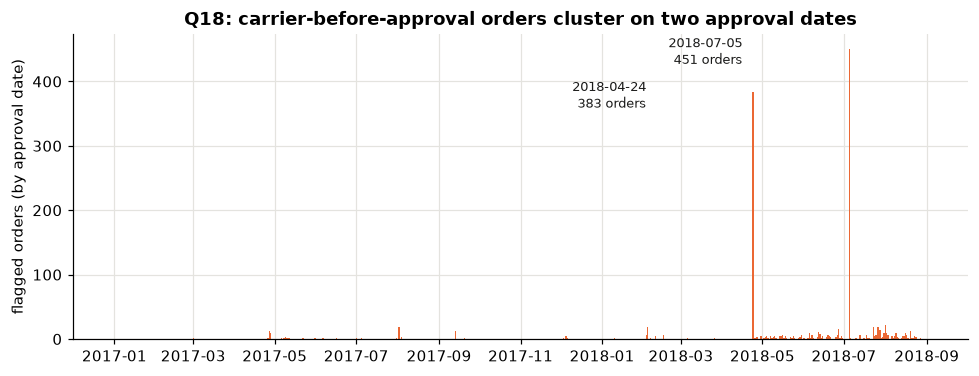

In [7]:
daily = fl.groupby(fl.order_approved_at.dt.to_period("D")).size()
idx = pd.period_range("2017-01-01", "2018-09-01", freq="D")
daily = daily.reindex(idx, fill_value=0)
fig, ax = plt.subplots(figsize=(10.5, 3.6))
ax.bar(daily.index.to_timestamp(), daily.values, width=1.0, color=ACCENT)
for dte, n in top2.items():
    ax.annotate(f"{dte}\n{n} orders", xy=(pd.Timestamp(dte), n), xytext=(-70, -10),
                textcoords="offset points", fontsize=8.5, color=INK, ha="right")
ax.set_ylabel("flagged orders (by approval date)")
ax.set_title("Q18: carrier-before-approval orders cluster on two approval dates")
fig.savefig(CHARTS / "DQ1_carrier_before_approval_by_approval_date.png"); plt.show()

In [8]:
sellers_per = items[items.order_id.isin(fl.order_id)].groupby("seller_id").order_id.nunique()
print(f"Sellers involved: {sellers_per.size:,} (largest {sellers_per.max()} orders) -> not seller-driven")
st = o[cba].customer_state.value_counts(normalize=True).mul(100).head(4)
allst = o[both].customer_state.value_counts(normalize=True).mul(100).reindex(st.index)
print("\nState mix, flagged vs all (%):"); print(pd.DataFrame({"flagged": st.round(1), "all": allst.round(1)}).to_string())
print("-> mirrors the overall order mix: not region-driven")

Sellers involved: 584 (largest 51 orders) -> not seller-driven

State mix, flagged vs all (%):
                flagged   all
customer_state               
SP                 42.4  41.8
MG                 11.8  11.7
RJ                 10.2  13.0
RS                  6.0   5.5
-> mirrors the overall order mix: not region-driven


### A3. Related timestamp inconsistencies — how they nest

In [9]:
c_before_purchase = both & (o.order_delivered_carrier_date < o.order_purchase_timestamp)
cust_before_appr  = o.order_delivered_customer_date.notna() & o.order_approved_at.notna() & \
                    (o.order_delivered_customer_date < o.order_approved_at)
q08 = o.order_delivered_customer_date.notna() & o.order_delivered_carrier_date.notna() & \
      (o.order_delivered_customer_date < o.order_delivered_carrier_date)
appr_before_purch = o.order_approved_at.notna() & (o.order_approved_at < o.order_purchase_timestamp)
print(f"carrier before APPROVAL (Q18)            {int(cba.sum()):>6,}")
print(f"  carrier before PURCHASE                {int(c_before_purchase.sum()):>6,}   subset of Q18: {bool((c_before_purchase <= cba).all())}")
print(f"  customer delivery before approval      {int(cust_before_appr.sum()):>6,}   subset of Q18: {bool((cust_before_appr <= cba).all())}")
print(f"customer delivery before carrier (Q08)   {int(q08.sum()):>6,}   overlap with Q18: {int((q08 & cba).sum())}")
print(f"approval before purchase                 {int(appr_before_purch.sum()):>6,}")
cbp_days = o[c_before_purchase].order_approved_at.dt.date.value_counts()
print(f"\nThe {int(c_before_purchase.sum())} carrier-before-purchase orders: largest single approval date holds "
      f"{cbp_days.max()} -> NOT the batch pattern.")
print("A handoff before the purchase cannot be explained by a late approval:")
print("these point to errors in the carrier timestamp itself.")

carrier before APPROVAL (Q18)             1,359
  carrier before PURCHASE                   166   subset of Q18: True
  customer delivery before approval          61   subset of Q18: True
customer delivery before carrier (Q08)       23   overlap with Q18: 0
approval before purchase                      0

The 166 carrier-before-purchase orders: largest single approval date holds 10 -> NOT the batch pattern.
A handoff before the purchase cannot be explained by a late approval:
these point to errors in the carrier timestamp itself.


### A4. Delivery-stage recalculation — does Insight 12 survive?

Overall delivery metrics use purchase → delivery and are **unaffected**. Only the
*stage* breakdown uses the approval and carrier timestamps, so only it can be
distorted. The corrected population is `stage_timing_valid`: all four timestamps
present and non-decreasing, so no stage can be negative.

In [10]:
m = o[meas & o.order_delivered_customer_date.notna()].copy()
day_ = lambda a, b: (m[b] - m[a]).dt.total_seconds() / 86400
m["s1"] = day_("order_purchase_timestamp", "order_approved_at")
m["s2"] = day_("order_approved_at", "order_delivered_carrier_date")
m["s3"] = day_("order_delivered_carrier_date", "order_delivered_customer_date")
m["tot"] = day_("order_purchase_timestamp", "order_delivered_customer_date")
valid = ((m.s1 >= 0) & (m.s2 >= 0) & (m.s3 >= 0))                     # recomputed population
trunc = lambda a, b: np.floor((m[b] - m[a]).dt.total_seconds() / 3600) / 24   # original hour-truncation

rows = [("superseded: hour-truncated, all", len(m), trunc("order_purchase_timestamp","order_approved_at").mean(),
         trunc("order_approved_at","order_delivered_carrier_date").mean(),
         trunc("order_delivered_carrier_date","order_delivered_customer_date").mean(), m.tot.mean(),
         int((m.s2 < 0).sum() + (m.s3 < 0).sum())),
        ("exact, all", len(m), m.s1.mean(), m.s2.mean(), m.s3.mean(), m.tot.mean(),
         int((m.s2 < 0).sum() + (m.s3 < 0).sum())),
        ("CORRECTED: exact, valid only", int(valid.sum()), m[valid].s1.mean(), m[valid].s2.mean(),
         m[valid].s3.mean(), m[valid].tot.mean(), 0)]
stages = pd.DataFrame(rows, columns=["method", "orders", "purchase_to_approval", "approval_to_carrier",
                                     "carrier_to_customer", "total", "negative_intervals"]).round(2)
display(stages)
v = m[valid]
shares = (v[["s1", "s2", "s3"]].sum() / v.tot.sum() * 100).round(1)
print(f"Corrected shares ({int(valid.sum()):,} orders): purchase->approval {shares.s1}% | "
      f"approval->carrier {shares.s2}% | carrier->customer {shares.s3}%")
print(f"stages sum to total exactly on the valid population: {bool(np.allclose(v.s1+v.s2+v.s3, v.tot))}")

,method,orders,purchase_to_approval,approval_to_carrier,carrier_to_customer,total,negative_intervals
0,"superseded: hour-truncated, all",96461,0.41,2.78,9.31,12.56,1373
1,"exact, all",96461,0.43,2.80,9.33,12.56,1373
2,"CORRECTED: exact, valid only",95088,0.40,2.85,9.36,12.62,0


Corrected shares (95,088 orders): purchase->approval 3.2% | approval->carrier 22.6% | carrier->customer 74.2%
stages sum to total exactly on the valid population: True


**Reading it.** Removing the 1,373 rows with impossible sequences barely moves anything:
approval → carrier 2.78 → 2.85 days, carrier → customer 9.31 → 9.36 days, and the
last-mile share is **74.2%**. *Insight 12 is robust.* The anomaly was real but too
small and too short (two-thirds under 24 hours) to change the conclusion.

---
## B · Q19 — Reviews "before delivery"

### B1. Which timestamp means "submitted"?

In [11]:
print("Share of values exactly at 00:00:00:")
print(f"  review_creation_date     {midnight(r.review_creation_date):6.2f}%   <- date only: when the survey was SENT")
print(f"  review_answer_timestamp  {midnight(r.review_answer_timestamp):6.2f}%   <- full timestamp: when the customer ANSWERED")
print(f"\nanswer earlier than creation (impossible): {int((r.review_answer_timestamp < r.review_creation_date).sum())}")

rv = r.merge(o[["order_id", "order_delivered_customer_date", "order_estimated_delivery_date",
                "delay_days", "delivery_measurable", "is_late"]], on="order_id", how="left")
assert len(rv) == len(r)
dm = rv[rv.order_delivered_customer_date.notna()].copy()
sent_ts  = dm.review_creation_date < dm.order_delivered_customer_date
sent_day = dm.review_creation_date.dt.date < dm.order_delivered_customer_date.dt.date
same_day = dm.review_creation_date.dt.date == dm.order_delivered_customer_date.dt.date
answered = dm.review_answer_timestamp < dm.order_delivered_customer_date
print(f"\nReviews on orders with a delivery date: {len(dm):,}")
print(f"  A survey SENT before delivery (date vs timestamp - the audit's 8,320) : {int(sent_ts.sum()):,}")
print(f"      of which sent on the SAME calendar day as delivery               : {int((sent_ts & same_day).sum()):,}")
print(f"  B survey sent on an earlier DAY                                      : {int(sent_day.sum()):,}")
print(f"  C customer ANSWERED before delivery  <- correct definition           : {int(answered.sum()):,}  ({answered.mean()*100:.2f}%)")

Share of values exactly at 00:00:00:
  review_creation_date      99.91%   <- date only: when the survey was SENT
  review_answer_timestamp    0.00%   <- full timestamp: when the customer ANSWERED

answer earlier than creation (impossible): 0



Reviews on orders with a delivery date: 96,359
  A survey SENT before delivery (date vs timestamp - the audit's 8,320) : 8,320
      of which sent on the SAME calendar day as delivery               : 3,193
  B survey sent on an earlier DAY                                      : 5,127
  C customer ANSWERED before delivery  <- correct definition           : 4,795  (4.98%)


The audit's 8,320 compared a **date-only send date** against a precise delivery
**time**: a survey "sent" at 00:00 on the day of a 15:00 delivery counts as "before".
The right question — did the customer answer before the parcel arrived? — uses
`review_answer_timestamp`: **4,795 reviews (4.98%)**.

### B2. What triggers an early survey?

In [12]:
lag = (dm.review_creation_date.dt.normalize() - dm.order_delivered_customer_date.dt.normalize()).dt.days
print(f"survey sent 0-1 days after delivery : {lag.between(0, 1).mean()*100:.1f}% of all reviews")
eb = dm[answered]
after_est = (eb.review_creation_date.dt.normalize() - eb.order_estimated_delivery_date.dt.normalize()).dt.days
print("\nFor reviews answered BEFORE delivery - survey send date minus ESTIMATED date (days):")
print(after_est.value_counts().head(5).to_string())
print(f"\n{(eb.is_late == True).mean()*100:.1f}% of these belong to orders that were delivered late.")

survey sent 0-1 days after delivery : 92.2% of all reviews

For reviews answered BEFORE delivery - survey send date minus ESTIMATED date (days):
2    3190
3     536
1     234
4     187
6     121

94.2% of these belong to orders that were delivered late.


**Mechanism.** The survey goes out the day after delivery — or, if the parcel has not
arrived, about **two days after the estimated date**. Late parcels are therefore
surveyed while the customer is still waiting. This is how the survey process works,
not invalid data: Q19 is an **analytical limitation**, flagged and never removed.

In [13]:
ans_rows = dm.assign(answered_before=answered)
s = ans_rows.groupby("answered_before").review_score.agg(
    reviews="size", avg_score="mean",
    pct_1star=lambda x: (x == 1).mean() * 100, pct_5star=lambda x: (x == 5).mean() * 100).round(3)
s.index = ["answered after arrival", "answered BEFORE arrival"]
print("Review grain:"); print(s.to_string())

how_early = ((eb.order_delivered_customer_date - eb.review_answer_timestamp).dt.total_seconds() / 86400)
he = pd.cut(how_early, [0, 1, 3, 7, 14, np.inf], labels=["<1d", "1-3d", "3-7d", "7-14d", "14d+"], right=False).value_counts().sort_index()
print("\nHow long before arrival they answered:"); print(he.to_string())

mo = ans_rows.groupby(ans_rows.order_delivered_customer_date.dt.to_period("M")).answered_before.agg(["size", "sum", "mean"])
mo = mo.loc["2017-01":"2018-08"]; mo["mean"] = (mo["mean"] * 100).round(2)
print("\nBy delivery month (stable window) - highest rates:"); print(mo.sort_values("mean", ascending=False).head(4).to_string())

multi = ans_rows.groupby("order_id").answered_before.agg(["size", "sum"])
multi = multi[multi["size"] > 1]
print(f"\nOrders with >1 review: {len(multi):,}; with reviews BOTH before and after arrival: "
      f"{int(((multi['sum'] > 0) & (multi['sum'] < multi['size'])).sum()):,}")
print("-> the flag lives at REVIEW grain and filtering must happen before averaging per order.")

Review grain:
                         reviews  avg_score  pct_1star  pct_5star
answered after arrival     91564      4.279      6.759     61.821
answered BEFORE arrival     4795      1.803     67.153      9.468

How long before arrival they answered:
<1d       587
1-3d      899
3-7d     1264
7-14d    1056
14d+      989

By delivery month (stable window) - highest rates:
                               size   sum   mean
order_delivered_customer_date                   
2018-04                        7807  1069  13.69
2018-03                        6871   652   9.49
2018-01                        6567   504   7.67
2017-12                        7197   429   5.96



Orders with >1 review: 525; with reviews BOTH before and after arrival: 115
-> the flag lives at REVIEW grain and filtering must happen before averaging per order.


---
## C · Sensitivity — does the delivery–satisfaction finding survive?

**Grain:** one average score per **order**, exactly as Insight 9 / SQL Q26.
**Analysis 1:** all reviews of the order. **Analysis 2:** reviews answered *after*
arrival only — filtered at review grain first, then averaged per order.
**Denominator:** delivered orders with ≥ 1 qualifying review.
**Uncertainty:** 95% intervals — normal approximation for the mean, Wilson for the
1-star share — because some Analysis-2 groups are small.

In [14]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z*z/n; c = p + z*z/(2*n); h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))
    return ((c - h) / d * 100, (c + h) / d * 100)

def bucket(x):
    return np.select([x <= -15, x <= -7, x <= 0, x <= 7, x <= 15],
                     ["a. 15+ days early", "b. 7-15 days early", "c. 0-7 days early (on time)",
                      "d. 1-7 days late", "e. 8-15 days late"], "f. more than 15 days late")

deliv = o[o.delivery_measurable].copy(); deliv["bucket"] = bucket(deliv.delay_days.values)
rr = r.merge(o[["order_id", "order_delivered_customer_date"]], on="order_id")
rr = rr[rr.order_id.isin(deliv.order_id)]
rr["before"] = rr.review_answer_timestamp < rr.order_delivered_customer_date

def summarise(rev, label):
    sc = rev.groupby("order_id").review_score.mean().rename("score")
    j = deliv[["order_id", "bucket"]].merge(sc, on="order_id")
    out = []
    for b, g in j.groupby("bucket"):
        n = len(g); k = int((g.score == 1).sum()); sd = g.score.std(ddof=1)
        lo, hi = wilson(k, n)
        out.append({"bucket": b, f"{label}_orders": n, f"{label}_avg": round(g.score.mean(), 3),
                    f"{label}_avg_ci": f"±{1.96*sd/np.sqrt(n):.2f}" if n > 1 else "",
                    f"{label}_1star%": round(k / n * 100, 1), f"{label}_1star_ci": f"{lo:.1f}-{hi:.1f}"})
    return pd.DataFrame(out).set_index("bucket")

sens = summarise(rr, "all").join(summarise(rr[~rr.before], "after"))
display(sens)

,all_orders,all_avg,all_avg_ci,all_1star%,all_1star_ci,after_orders,after_avg,after_avg_ci,after_1star%,after_1star_ci
bucket,,,,,,,,,,
a. 15+ days early,29458,4.318,±0.01,6.7,6.4-7.0,29414,4.319,±0.01,6.7,6.4-7.0
b. 7-15 days early,41476,4.316,±0.01,6.3,6.1-6.5,41389,4.316,±0.01,6.3,6.0-6.5
c. 0-7 days early (on time),17234,4.201,±0.02,7.0,6.7-7.4,17193,4.202,±0.02,7.0,6.7-7.4
d. 1-7 days late,4409,3.184,±0.05,29.5,28.2-30.9,3055,3.860,±0.05,11.1,10.0-12.3
e. 8-15 days late,1918,1.733,±0.06,68.5,66.4-70.5,106,3.660,±0.28,17.9,11.8-26.3
f. more than 15 days late,1335,1.726,±0.07,68.8,66.2-71.2,19,2.895,±0.73,31.6,15.4-54.0


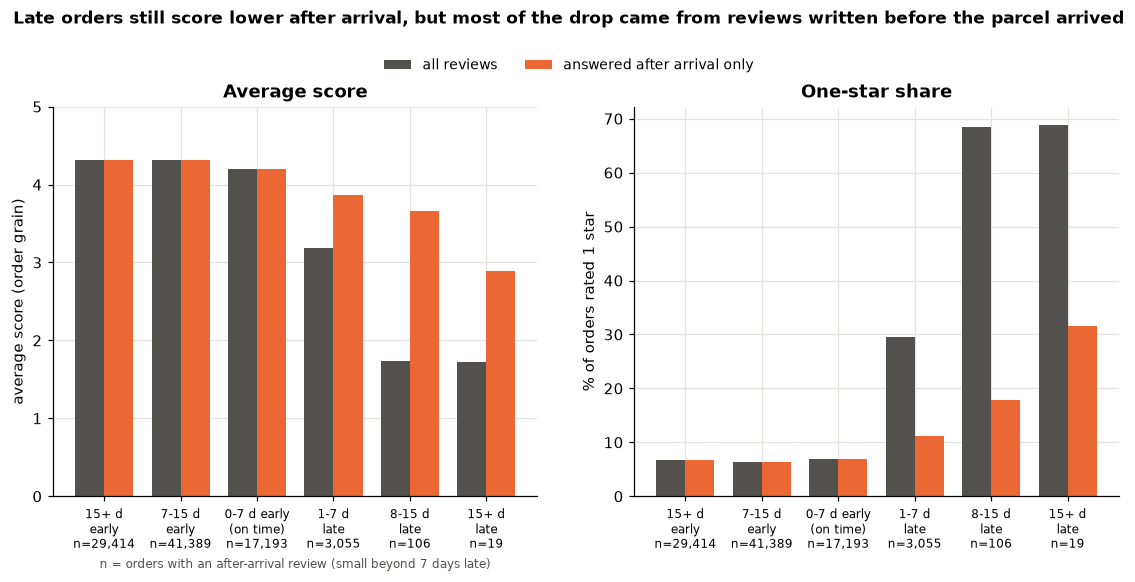

In [15]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
x = np.arange(len(sens)); w = 0.38
short = ["15+ d\nearly", "7-15 d\nearly", "0-7 d early\n(on time)", "1-7 d\nlate", "8-15 d\nlate", "15+ d\nlate"]
lab = [f"{s}\nn={n:,}" for s, n in zip(short, sens.after_orders)]
for ax, col_all, col_after, ylab, title in [
        (a1, "all_avg", "after_avg", "average score (order grain)", "Average score"),
        (a2, "all_1star%", "after_1star%", "% of orders rated 1 star", "One-star share")]:
    ax.bar(x - w/2, sens[col_all], w, color=SOFT, label="all reviews")
    ax.bar(x + w/2, sens[col_after], w, color=ACCENT, label="answered after arrival only")
    ax.set_xticks(x); ax.set_xticklabels(lab, fontsize=7.8); ax.set_ylabel(ylab); ax.set_title(title)
a1.set_ylim(0, 5)
a1.set_xlabel("n = orders with an after-arrival review (small beyond 7 days late)", fontsize=8, color=SOFT)
h, l = a1.get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0), fontsize=9)
fig.suptitle("Late orders still score lower after arrival, but most of the drop came from reviews written before the parcel arrived",
             fontweight="bold", y=1.07, fontsize=11)
fig.savefig(CHARTS / "DQ2_review_timing_sensitivity.png"); plt.show()

In [16]:
on = sens.loc["c. 0-7 days early (on time)"]
print("Is late delivery still associated with lower scores among reviews written after arrival?")
for b in ["d. 1-7 days late", "e. 8-15 days late", "f. more than 15 days late"]:
    row = sens.loc[b]
    print(f"  {b:<28} after-arrival avg {row.after_avg:.3f} (n={row.after_orders:,}, {row.after_avg_ci}) "
          f"vs on time {on.after_avg:.3f}  |  1-star {row['after_1star%']}% [{row.after_1star_ci}] vs {on['after_1star%']}%")
late_after = rr[~rr.before].groupby("order_id").review_score.mean().rename("score").reset_index() \
               .merge(deliv[["order_id", "is_late"]], on="order_id")
gl = late_after.groupby("is_late").score.agg(["size", "mean"])
print(f"\nAll late vs not late, after-arrival only: late {gl.loc[True,'mean']:.3f} (n={int(gl.loc[True,'size']):,}) "
      f"vs not late {gl.loc[False,'mean']:.3f} (n={int(gl.loc[False,'size']):,})")
print("\nHow much of each late bucket survives Analysis 2:")
for b in ["d. 1-7 days late", "e. 8-15 days late", "f. more than 15 days late"]:
    print(f"  {b:<28} {sens.loc[b,'after_orders']:>5,} of {sens.loc[b,'all_orders']:>5,} orders "
          f"({sens.loc[b,'after_orders']/sens.loc[b,'all_orders']*100:.0f}%)")

Is late delivery still associated with lower scores among reviews written after arrival?
  d. 1-7 days late             after-arrival avg 3.860 (n=3,055, ±0.05) vs on time 4.202  |  1-star 11.1% [10.0-12.3] vs 7.0%
  e. 8-15 days late            after-arrival avg 3.660 (n=106, ±0.28) vs on time 4.202  |  1-star 17.9% [11.8-26.3] vs 7.0%
  f. more than 15 days late    after-arrival avg 2.895 (n=19, ±0.73) vs on time 4.202  |  1-star 31.6% [15.4-54.0] vs 7.0%

All late vs not late, after-arrival only: late 3.848 (n=3,180) vs not late 4.295 (n=87,996)

How much of each late bucket survives Analysis 2:
  d. 1-7 days late             3,055 of 4,409 orders (69%)
  e. 8-15 days late              106 of 1,918 orders (6%)
  f. more than 15 days late       19 of 1,335 orders (1%)


**Reading it.**

- The association **survives in direction**: among reviews written after arrival, late
  orders still score lower than on-time ones, and the one-star share still rises with
  lateness.
- The **magnitude does not survive.** "8–15 days late → 1.73 stars, 68.5% one-star"
  becomes ≈ 3.66 stars and ≈ 18% one-star once pre-arrival reviews are removed. The
  steep cliff in Insight 9 is mostly customers rating **while still waiting** — the
  survey reaches them about two days after the promised date.
- **Small samples.** Only 106 of 1,918 orders 8–15 days late, and 19 of 1,335 orders
  more than 15 days late, keep a post-arrival review. The intervals above are wide; the
  15+ day bucket cannot support a precise conclusion.
- **Selection.** Customers who still review after a very late arrival may differ from
  those who reviewed while waiting, so Analysis 2 is a robustness check, not an unbiased
  estimate of "satisfaction with a late parcel".

What *is* robust: the pre-arrival reviews themselves average about **1.8 stars with
two-thirds one-star**, so the platform's survey timing measurably depresses its public
rating — which is exactly the point of Insight 13.

---
## D · Independent cross-check — stored flags and MySQL

In [17]:
chk = []
chk.append(("Q18 stored flag == recomputed", bool((o.carrier_before_approval == cba).all())))
o_valid = (o.order_delivered_customer_date.notna() & both
           & (o.order_approved_at >= o.order_purchase_timestamp)
           & (o.order_delivered_carrier_date >= o.order_approved_at)
           & (o.order_delivered_customer_date >= o.order_delivered_carrier_date))
chk.append(("stage_timing_valid stored == recomputed", bool((o.stage_timing_valid == o_valid).all())))
rb = r.merge(o[["order_id", "order_delivered_customer_date"]], on="order_id")
re_c = rb.review_answer_timestamp < rb.order_delivered_customer_date
stored = rb.review_before_delivery.map({True: True, False: False, "True": True, "False": False})
known = rb.order_delivered_customer_date.notna()
chk.append(("Q19 stored flag == recomputed (delivered orders)", bool((stored[known] == re_c[known]).all())))
chk.append(("Q19 stored flag is NULL iff no delivery date", bool((stored.isna() == ~known).all())))

try:
    import mysql.connector
    cn = mysql.connector.connect(host="127.0.0.1", user="root", database="retailpulse")
    q = lambda s: (cur := cn.cursor(), cur.execute(s), cur.fetchone())[2]
    chk.append(("MySQL Q18 count == pandas", q("SELECT SUM(carrier_before_approval) FROM orders")[0] == int(cba.sum())))
    chk.append(("MySQL stage_timing_valid == pandas", q("SELECT SUM(stage_timing_valid) FROM orders")[0] == int(o_valid.sum())))
    chk.append(("MySQL Q19 count == pandas", q("SELECT SUM(review_before_delivery) FROM order_reviews")[0] == int(re_c[known].sum())))
    s3 = q('''SELECT AVG(TIMESTAMPDIFF(SECOND, order_delivered_carrier_date, order_delivered_customer_date))/86400,
                     100*SUM(TIMESTAMPDIFF(SECOND, order_delivered_carrier_date, order_delivered_customer_date))
                        /SUM(TIMESTAMPDIFF(SECOND, order_purchase_timestamp, order_delivered_customer_date))
              FROM orders WHERE stage_timing_valid = 1''')
    chk.append(("MySQL corrected carrier->customer days == pandas", abs(float(s3[0]) - m[valid].s3.mean()) < 1e-6))
    chk.append(("MySQL last-mile share == pandas", abs(float(s3[1]) - shares.s3) < 0.05))
    e815 = q('''SELECT COUNT(*), AVG(sc) FROM (SELECT r.order_id, AVG(r.review_score) sc FROM order_reviews r
               JOIN orders o ON o.order_id=r.order_id WHERE o.delivery_measurable=1 AND r.review_before_delivery=0
               AND o.delay_days>7 AND o.delay_days<=15 GROUP BY r.order_id) t''')
    p815 = sens.loc["e. 8-15 days late"]
    chk.append(("MySQL 8-15 late after-arrival (n, avg) == pandas",
                e815[0] == p815.after_orders and abs(float(e815[1]) - p815.after_avg) < 0.0005))
    cn.close()
except Exception as e:
    print(f"MySQL not reachable ({type(e).__name__}); stored-flag checks only.")

res = pd.DataFrame(chk, columns=["check", "pass"]); display(res)
print(f"PASS {int(res['pass'].sum())} / {len(res)}")
assert res["pass"].all(), "a cross-check failed"

,check,pass
0,Q18 stored flag == recomputed,True
1,stage_timing_valid stored == recomputed,True
2,Q19 stored flag == recomputed (delivered orders),True
3,Q19 stored flag is NULL iff no delivery date,True
4,MySQL Q18 count == pandas,True
5,MySQL stage_timing_valid == pandas,True
6,MySQL Q19 count == pandas,True
7,MySQL corrected carrier->customer days == pandas,True
8,MySQL last-mile share == pandas,True
9,"MySQL 8-15 late after-arrival (n, avg) == pandas",True


PASS 10 / 10


---
## E · Conclusions

| | Finding | Evidence |
|---|---|---|
| **Q18 size** | 1,359 orders (1.39% of orders with both timestamps); 1,350 delivered | §A1 |
| **Q18 cause** | Not boleto. Consistent with **late-recorded approvals**: 61% fall on two approval dates (2018-04-24, 2018-07-05) when 3–4× a normal day's approvals were recorded within 7–9 hours for a week's backlog. The 166 carrier-before-*purchase* cases instead point to carrier timestamp errors. Root cause not determinable from the data | §A2–A3 |
| **Q18 treatment** | Flag `carrier_before_approval`; stage metrics use `stage_timing_valid` only. Nothing deleted, no timestamp altered | §A4 |
| **Insight 12** | **Robust.** Last mile = 74.2% of delivery time on the corrected population | §A4 |
| **Q19 size** | **4,795 reviews (4.98%)** answered before arrival — not 8,320, which compared a date-only *send* date to a delivery *time* | §B1 |
| **Q19 cause** | Survey sent ~2 days after the estimated date when the parcel has not arrived; 94% of these are late orders. An analytical limitation, not invalid data | §B2 |
| **Insight 9** | **Direction robust, magnitude not.** Late orders still score lower after arrival, but the 1.73-star / 68.5% one-star cliff is mostly pre-arrival reviews; after-arrival late samples are small | §C |
| **Insight 13** | **Strengthened.** Pre-arrival reviews average ~1.8 stars | §B2, §C |